# Final structure and fit

At the final fit of the selection (`src/final_analysis.py`):

* the structural check of all free parameters (Stigter and Molenaar);
* the Fisher information $F = J^\top J$ of the free parameters (except those kept free by design): rank, correlations
  from $F^{-1}$ and the coefficient of variation $\sqrt{(F^{-1})_{ii}}$ (the standard deviation of $\ln\theta_i$);
* the fit: objective per condition, in-sample prediction of the measured metabolites and linearly independent fluxes,
  fitted drains against the data.

The Fisher information is a local, linear measure. Whether each free parameter is practically identifiable is
decided by the bootstrap and the profile likelihood (`bootstrap.ipynb`, `profiles.ipynb`). The last section writes
`OUT/REPORT.md`; re-run it after those notebooks.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

import final_analysis
from report import build_report

FINAL = os.path.join(OUT, "final")

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

In [3]:
if RUN:
    final_analysis.run_final_analysis(OUT, params)
else:
    print("RUN is False: the final analysis is loaded from", FINAL)

RUN is False: the final analysis is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model/final


In [4]:
summary = json.load(open(os.path.join(FINAL, "final_summary.json")))
structure = pd.read_csv(os.path.join(FINAL, "final_structure.csv"), index_col=0)
print("%d free, %d fixed; structural zeros %d; Fisher information full rank %s (smallest singular value ratio %.2e); max |r| %.3f" % (
    summary["n_free"], int((structure["status"] == "fixed").sum()), summary["n_structural_zeros"], summary["full_rank"],
    summary["sigma_ratio_min"], summary["max_abs_r"]))
print("kept free by design:", summary["kept_free_by_design"] or "none")
print("sensitivities missing for:", summary["sens_failed_conditions"] or "none")
structure[structure["status"] == "free"][["value", "sensitivity", "cv_percent"]].round(4)

14 free, 23 fixed; structural zeros 0; Fisher information full rank True (smallest singular value ratio 1.17e-04); max |r| 0.897
kept free by design: none
sensitivities missing for: ['KO04']


,value,sensitivity,cv_percent
param,,,
v_max_1,80.2561,0.0000,13005.4882
Ks_g6p_pgi,0.0050,0.0000,28818.0085
kcat_f_2,978.1748,0.0023,226.0584
kcat_f_3,974.4076,0.0986,11.8237
Ks_fbp_4,0.0010,0.0092,139.5108
kcat_f_4,2.6973,0.1754,5.6898
kcat_f_5,6865.9168,0.0005,11496.4799
kcat_f_6,622.6176,0.0002,24721.9831
kcat_f_7,875.8411,0.0016,3254.8590


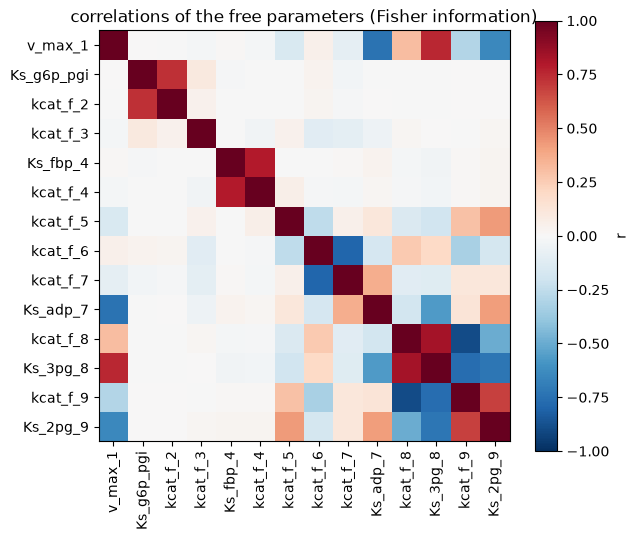

In [5]:
corr = pd.read_csv(os.path.join(FINAL, "final_correlation.csv"), index_col=0)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
fig.colorbar(image, ax=ax, label="r")
ax.set_title("correlations of the free parameters (Fisher information)")
fig.tight_layout()
plt.show()

## Fit

In [6]:
print("objective %.4f, misfit s2 %.2f" % (summary["obj"], summary["s2"]))
print("metabolites: RMSE %.3f (mean predictor %.3f), R2 %.3f" % (summary["rmse_met"], summary["rmse_met_meanbaseline"], summary["r2_met_permean"]))
print("LI fluxes  : RMSE %.3f (mean predictor %.3f), R2 %.3f" % (summary["rmse_flux_li"], summary["rmse_flux_li_meanbaseline"], summary["r2_flux_li_permean"]))
print("parameters on a bound:", summary["theta_at_bounds"] or "none")
breakdown = pd.read_csv(os.path.join(FINAL, "objective_breakdown.csv"), index_col=0)
breakdown.round(4)

objective 10.9087, misfit s2 2.41
metabolites: RMSE 0.114 (mean predictor 0.158), R2 0.477
LI fluxes  : RMSE 0.359 (mean predictor 0.727), R2 0.756
parameters on a bound: ['Ks_fbp_4']


,flux_wsse,met_wsse,u_wsse,total,termination
KO02,0.0029,0.1229,0.0,0.1258,optimal
KO03,0.0000,0.0666,0.0,0.0666,optimal
KO04,0.0000,0.0000,0.0,0.0000,optimal
KO05,5.6334,27.2070,0.0,32.8404,optimal
KO07,0.0060,0.9865,0.0,0.9926,optimal
KO08,0.0001,0.8694,0.0,0.8695,optimal
KO10,0.4611,0.0019,0.0,0.4630,optimal
KO11,5.1248,2.9778,0.0,8.1026,optimal
KO12,0.0111,0.4087,0.0,0.4198,optimal
KO13,1.2586,1.8496,0.0,3.1082,optimal


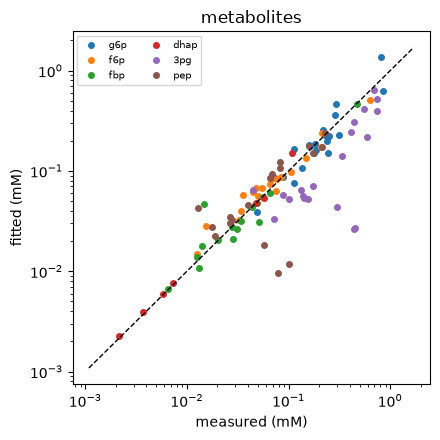

In [7]:
real = pd.read_csv(os.path.join(FINAL, "pred_insample_real.csv"), index_col=0)
predicted = pd.read_csv(os.path.join(FINAL, "pred_insample_predicted.csv"), index_col=0)
met_columns = [c for c in real.columns if c.startswith("C_") and real[c].notna().any()]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for column in met_columns:
    ax.loglog(real[column], predicted[column], "o", ms=4, label=column[2:])
limits = [np.nanmin(real[met_columns].to_numpy()) / 2, np.nanmax(real[met_columns].to_numpy()) * 2]
ax.plot(limits, limits, "k--", lw=1)
ax.set_xlabel("measured (mM)")
ax.set_ylabel("fitted (mM)")
ax.legend(fontsize=7, ncol=2)
ax.set_title("metabolites")
fig.tight_layout()
plt.show()

## REPORT.md

In [8]:
text = build_report(OUT)
if RUN:
    open(os.path.join(OUT, "REPORT.md"), "w").write(text)
print(text)

# Flux model (results/flux_model)

## Identifiable structure
14 free / 23 fixed. Structural zeros of the rate laws: 0. Fisher information of the 14 analysed free parameters: full rank True (smallest singular value ratio 1.17e-04), max |r| 0.897. Kept free by design (not identifiable): none.
```
           ident_class      value  sensitivity  cv_percent  ci_ratio_97.5_over_2.5  practically_identifiable profile_class
param                                                                                                                     
v_max_1           free    80.2561       0.0000  13005.4882                  1.3827                     False     one_sided
Ks_g6p_pgi        free     0.0050       0.0000  28818.0085               3731.3802                     False          flat
kcat_f_2          free   978.1748       0.0023    226.0584                  2.1669                     False     one_sided
kcat_f_3          free   974.4076       0.0986     11.8237                  1.4294       